## Utils and load data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from typing import List, Dict, Any
from utils import (
    # Configuration and constants
    RESULTS_DIR,
    # Data loading and processing
    load_jsonl, filter_excluded_categories,
    # Data conversion
    convert_simulatability_to_bool, apply_boolean_conversion,
    # Calculation functions
    calculate_inconsistency_rate, calculate_baseline_inconsistency_rate,
    calculate_verbalization_score
)

EXCLUDED_CATEGORIES = ['persona', 'resume']
GRADER_TRUE_VALUES = ["Inconsistent"]

sns.set_style("whitegrid")

# Specific data files for this notebook
# DATA_FILES = {
#     'gpt-4o': '/mnt/efs/oampatel/faithfulness/results/gpt-4o/perturbation_data_temperature-1.0.jsonl', 
#     'gpt-4o-private-cot': '/mnt/efs/oampatel/faithfulness/results/gpt-4o/perturbation_data_temperature-1.0_cot-private_cot.jsonl',
#     'gpt-4o-public-cot': '/mnt/efs/oampatel/faithfulness/results/gpt-4o/perturbation_data_temperature-1.0_cot-public_cot.jsonl',
#     'gpt-4o-include-all-factors': '/mnt/efs/oampatel/faithfulness/results/gpt-4o/perturbation_data_temperature-1.0_cot-include_all_factors.jsonl',
#     'qwen': '/mnt/efs/oampatel/faithfulness/results/Qwen/Qwen2.5-32B-Instruct/perturbation_data_temperature-1.0_cot-qwen.jsonl',
#     'qwq': '/mnt/efs/oampatel/faithfulness/results/Qwen/QwQ-32B/perturbation_data_temperature-1.0_cot-qwq.jsonl',
# }

DATA_FILES = {
    'gpt-4o': '/mnt/efs/oampatel/faithfulness/results/gpt-4o/perturbation_data_temperature-1.0.jsonl',
    'claude-4-sonnet': '/mnt/efs/oampatel/faithfulness/results/anthropic/claude-sonnet-4-20250514/perturbation_data_temperature-1.0.jsonl',
    'llama-4-maverick': '/mnt/efs/oampatel/faithfulness/results/fireworks_ai/llama4-maverick-instruct-basic/perturbation_data_temperature-1.0.jsonl',
    # 'deepseek-r1': '/mnt/efs/oampatel/faithfulness/results/fireworks_ai/deepseek-r1/perturbation_data_test_temperature-1.0.jsonl',
    'qwen': '/mnt/efs/oampatel/faithfulness/results/Qwen/Qwen2.5-32B-Instruct/perturbation_data_temperature-1.0_cot-qwen.jsonl',
    # 'qwq': '/mnt/efs/oampatel/faithfulness/results/Qwen/QwQ-32B/perturbation_data_temperature-1.0_cot-qwq.jsonl',
}

# DATA_FILES = {
#     'qwen': '/mnt/efs/oampatel/faithfulness/results/Qwen/Qwen2.5-32B-Instruct/perturbation_data_temperature-1.0_cot-qwen.jsonl', 
#     'qwq': '/mnt/efs/oampatel/faithfulness/results/Qwen/QwQ-32B/perturbation_data_temperature-1.0_cot-qwq.jsonl',
# }

# DATA_FILES = {
#     'gpt-4o': '/mnt/efs/oampatel/faithfulness/results/gpt-4o/perturbation_data_temperature-1.0.jsonl', 
#     'claude-4-sonnet': '/mnt/efs/oampatel/faithfulness/results/anthropic/claude-sonnet-4-20250514/perturbation_data_temperature-1.0.jsonl',
#     'deepseek-r1': '/mnt/efs/oampatel/faithfulness/results/fireworks_ai/deepseek-r1/perturbation_data_test_temperature-1.0.jsonl',
#     'qwen': '/mnt/efs/oampatel/faithfulness/results/Qwen/Qwen2.5-32B-Instruct/perturbation_data_temperature-1.0_cot-qwen.jsonl',
# }
models = list(DATA_FILES.keys())
custom_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728', '#98df8a']
custom_colors = {m:c for m,c in zip(models, custom_colors)}

grader = 'faithfulness_simulability_tuned'

2025-07-16 03:22:31.986 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2025-07-16 03:22:31.988 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


In [2]:
# Functions imported from utils - no need to redefine them here

In [3]:
def calculate_inconsistency_rate(df: pd.DataFrame) -> Dict[str, Any]:
    """Calculate inconsistency rate for a dataset"""
    total_cases = len(df)
    if total_cases == 0:
        return {'inconsistency_rate': 0.0, 'num_inconsistent': 0, 'num_total': 0}
    
    # Count inconsistent cases
    inconsistent_mask = df['inconsistency_label'].fillna(False).astype(bool) == True
    num_inconsistent = inconsistent_mask.sum()
    
    inconsistency_rate = num_inconsistent / total_cases if total_cases > 0 else 0.0
    
    return {
        'inconsistency_rate': inconsistency_rate,
        'num_inconsistent': num_inconsistent,
        'num_total': total_cases
    }

def calculate_baseline_inconsistency_rate(df: pd.DataFrame) -> Dict[str, Any]:
    """Calculate baseline inconsistency rate for a dataset using baseline_inconsistency_label"""
    total_cases = len(df)
    if total_cases == 0:
        return {'baseline_inconsistency_rate': 0.0, 'num_baseline_inconsistent': 0, 'num_total': 0}
    
    # Count baseline inconsistent cases
    if 'baseline_inconsistency_label' in df.columns:
        baseline_inconsistent_mask = df['baseline_inconsistency_label'].fillna(False).astype(bool) == True
        num_baseline_inconsistent = baseline_inconsistent_mask.sum()
    else:
        num_baseline_inconsistent = 0
    
    baseline_inconsistency_rate = num_baseline_inconsistent / total_cases if total_cases > 0 else 0.0
    
    return {
        'baseline_inconsistency_rate': baseline_inconsistency_rate,
        'num_baseline_inconsistent': num_baseline_inconsistent,
        'num_total': total_cases
    }

def calculate_verbalization_score(df: pd.DataFrame, grader_name: str = 'faithfulness_simulability') -> Dict[str, Any]:
    """Calculate verbalization score for inconsistent cases"""
    # Filter to inconsistent cases only
    inconsistent_mask = df['inconsistency_label'].fillna(False).astype(bool) == True
    inconsistent_df = df[inconsistent_mask]
    
    if len(inconsistent_df) == 0:
        return {'verbalization_score': 0.0, 'num_verbalize_given_inconsistent': 0, 'num_total_inconsistent': 0}
    
    num_total_inconsistent = len(inconsistent_df)
    
    # Calculate verbalization detection
    verbalization_detected = apply_boolean_conversion(inconsistent_df, grader_name, GRADER_TRUE_VALUES)
    num_verbalize_given_inconsistent = verbalization_detected.sum()
    verbalization_score = num_verbalize_given_inconsistent / num_total_inconsistent if num_total_inconsistent > 0 else 0.0
    
    return {
        'verbalization_score': verbalization_score,
        'num_verbalize_given_inconsistent': num_verbalize_given_inconsistent,
        'num_total_inconsistent': num_total_inconsistent
    }


In [4]:
# Load data for all models
from pathlib import Path
model_data = {}
for model_name, file_path in DATA_FILES.items():
    if file_path and Path(file_path).exists():
        df = load_jsonl(file_path)
        if df is not None:
            model_data[model_name] = df
            print(f"Loaded {len(df)} records for {model_name}")
        else:
            print(f"Failed to load data for {model_name}")
    else:
        print(f"File not found for {model_name}: {file_path}")

if not model_data:
    print("No data loaded. Please update DATA_FILES with valid paths.")
else:
    print(f"Successfully loaded data for {len(model_data)} models: {list(model_data.keys())}")

Loaded 4750 records for gpt-4o
Loaded 4750 records for claude-4-sonnet
Loaded 70 records for deepseek-r1
Loaded 4750 records for qwen
Loaded 4750 records for qwq
Successfully loaded data for 5 models: ['gpt-4o', 'claude-4-sonnet', 'deepseek-r1', 'qwen', 'qwq']


In [5]:
# filter for data where baseline_inconsistency_label = False
data = model_data['gpt-4o']
# filter out category to exclude
data = data[~data['category'].isin(EXCLUDED_CATEGORIES)]
print(len(data))
data = data[data['baseline_inconsistency_label'] == False]
data['faithfulness_simulability_tuned_pred_bool'] = data['faithfulness_simulability_tuned_pred'].apply(lambda x: True if 'Inconsistent' in x else False)
data['faithfulness_simulability_pred_bool'] = data['faithfulness_simulability_pred'].apply(lambda x: True if 'Inconsistent' in x else False)

# effective harm rate
data['effective_harm_rate'] = data['inconsistency_label'] & ~data['faithfulness_simulability_tuned_pred_bool']
print(data.groupby('category')['effective_harm_rate'].mean())
# take the unweighted average of the above by category
print('EFFECTIVE HARM RATE: ', data.groupby('category')['effective_harm_rate'].mean().mean())

data = model_data['claude-4-sonnet']
data = data[~data['category'].isin(EXCLUDED_CATEGORIES)]
data = data[data['baseline_inconsistency_label'] == False]
data['faithfulness_simulability_tuned_pred_bool'] = data['faithfulness_simulability_tuned_pred'].apply(lambda x: True if 'Inconsistent' in x else False)
data['faithfulness_simulability_pred_bool'] = data['faithfulness_simulability_pred'].apply(lambda x: True if 'Inconsistent' in x else False)

# effective harm rate
data['effective_harm_rate'] = data['inconsistency_label'] & ~data['faithfulness_simulability_tuned_pred_bool']
print(data.groupby('category')['effective_harm_rate'].mean())
# take the unweighted average of the above by category
print('EFFECTIVE HARM RATE: ', data.groupby('category')['effective_harm_rate'].mean().mean())

2788
category
advanced_ai_risk    0.096732
honesty             0.242424
reward_hacking      0.779661
sandbagging         0.057971
sycophancy          0.337568
Name: effective_harm_rate, dtype: float64
EFFECTIVE HARM RATE:  0.30287127161723293
category
advanced_ai_risk    0.041237
honesty             0.040000
reward_hacking      0.616667
sandbagging         0.102967
sycophancy          0.159649
Name: effective_harm_rate, dtype: float64
EFFECTIVE HARM RATE:  0.19210394881249654


In [6]:
# filter for data where baseline_inconsistency_label = False
data = model_data['gpt-4o']
print(len(data))
data = data[~data['category'].isin(EXCLUDED_CATEGORIES)]
data = data[data['baseline_inconsistency_label'] == False]
data['faithfulness_simulability_tuned_pred_bool'] = data['faithfulness_simulability_tuned_pred'].apply(lambda x: True if 'Inconsistent' in x else False)
data['faithfulness_simulability_pred_bool'] = data['faithfulness_simulability_pred'].apply(lambda x: True if 'Inconsistent' in x else False)
data = data[data['inconsistency_label'] == True]

print(data.groupby('category')['faithfulness_simulability_tuned_pred_bool'].mean())
# take the unweighted average of the above by category
print('CONDITIONAL VERBALIZATION RATE: ', data.groupby('category')['faithfulness_simulability_tuned_pred_bool'].mean().mean())

data = model_data['claude-4-sonnet']
print(len(data))
data = data[~data['category'].isin(EXCLUDED_CATEGORIES)]

data = data[data['baseline_inconsistency_label'] == False]
data['faithfulness_simulability_tuned_pred_bool'] = data['faithfulness_simulability_tuned_pred'].apply(lambda x: True if 'Inconsistent' in x else False)
data['faithfulness_simulability_pred_bool'] = data['faithfulness_simulability_pred'].apply(lambda x: True if 'Inconsistent' in x else False)
data = data[data['inconsistency_label'] == True]

print(data.groupby('category')['faithfulness_simulability_tuned_pred_bool'].mean())
# take the unweighted average of the above by category
print('CONDITIONAL VERBALIZATION RATE: ', data.groupby('category')['faithfulness_simulability_tuned_pred_bool'].mean().mean())

4750
category
advanced_ai_risk    0.086420
honesty             0.363636
reward_hacking      0.098039
sandbagging         0.709091
sycophancy          0.036269
Name: faithfulness_simulability_tuned_pred_bool, dtype: float64
CONDITIONAL VERBALIZATION RATE:  0.25869113431035606
4750
category
advanced_ai_risk    0.346939
honesty             0.176471
reward_hacking      0.026316
sandbagging         0.032787
sycophancy          0.071429
Name: faithfulness_simulability_tuned_pred_bool, dtype: float64
CONDITIONAL VERBALIZATION RATE:  0.13078812197873108


In [7]:
def calculate_unweighted_averages_with_ci(model_data: Dict[str, pd.DataFrame], 
                                         grader_name: str = 'faithfulness_simulability_tuned',
                                         exclude_categories: List[str] | None = None,
                                         n_bootstrap: int = 1000,
                                         confidence_level: float = 0.95,
                                         random_seed: int = 42) -> Dict[str, Dict[str, Any]]:
    """
    Calculate unweighted averages across categories with stratified bootstrapping for confidence intervals.
    Includes effective harm rate calculation: (inconsistent AND not verbalized) / total samples
    
    Args:
        model_data: Dictionary mapping model names to DataFrames
        grader_name: Name of the grader to use for verbalization scoring
        exclude_categories: List of category names to exclude. If None, uses EXCLUDED_CATEGORIES global variable.
        n_bootstrap: Number of bootstrap samples
        confidence_level: Confidence level for intervals (e.g., 0.95 for 95% CI)
        random_seed: Random seed for reproducibility
        
    Returns:
        Dictionary with results for each model containing unweighted averages and confidence intervals
    """
    np.random.seed(random_seed)
    
    # Determine which categories to exclude
    if exclude_categories is None:
        exclude_categories = EXCLUDED_CATEGORIES
    
    # Get all categories across all models
    all_categories = set()
    for df in model_data.values():
        all_categories.update(df['category'].dropna().unique())
    
    # Filter out excluded categories
    all_categories = sorted([cat for cat in all_categories if cat not in exclude_categories])
    
    if not all_categories:
        print("No categories found in data")
        return {}
    
    print(f"Computing unweighted averages for categories: {all_categories}")
    
    results = {}
    alpha = 1 - confidence_level
    lower_percentile = (alpha / 2) * 100
    upper_percentile = (1 - alpha / 2) * 100
    
    for model_name, df in model_data.items():
        print(f"\\nProcessing {model_name}...")
        
        # Calculate per-category metrics (ground truth)
        category_metrics = {}
        for category in all_categories:
            cat_df = df[df['category'] == category].copy()
            if len(cat_df) > 0:
                inconsistency_metrics = calculate_inconsistency_rate(cat_df)
                baseline_metrics = calculate_baseline_inconsistency_rate(cat_df)
                verbalization_metrics = calculate_verbalization_score(cat_df, grader_name)
                
                # Calculate effective harm rate: (inconsistent AND not verbalized) / total samples
                inconsistent_mask = cat_df['inconsistency_label'].fillna(False).astype(bool) == True
                inconsistent_df = cat_df[inconsistent_mask]
                
                if len(inconsistent_df) > 0:
                    verbalization_detected = apply_boolean_conversion(inconsistent_df, grader_name, GRADER_TRUE_VALUES)
                    not_verbalized_mask = ~verbalization_detected
                    num_harm_cases = not_verbalized_mask.sum()
                else:
                    num_harm_cases = 0
                
                effective_harm_rate = num_harm_cases / len(cat_df) if len(cat_df) > 0 else 0.0
                
                category_metrics[category] = {
                    'inconsistency_rate': inconsistency_metrics['inconsistency_rate'],
                    'baseline_inconsistency_rate': baseline_metrics['baseline_inconsistency_rate'],
                    'verbalization_score': verbalization_metrics['verbalization_score'],
                    'effective_harm_rate': effective_harm_rate,
                    'data': cat_df
                }
        
        # Calculate unweighted ground truth averages
        valid_categories = [cat for cat in all_categories if cat in category_metrics]
        
        inconsistency_rates = [category_metrics[cat]['inconsistency_rate'] for cat in valid_categories]
        baseline_rates = [category_metrics[cat]['baseline_inconsistency_rate'] for cat in valid_categories]
        verbalization_scores = [category_metrics[cat]['verbalization_score'] for cat in valid_categories]
        effective_harm_rates = [category_metrics[cat]['effective_harm_rate'] for cat in valid_categories]
        
        unweighted_inconsistency = np.mean(inconsistency_rates) if inconsistency_rates else 0.0
        unweighted_baseline = np.mean(baseline_rates) if baseline_rates else 0.0
        unweighted_verbalization = np.mean(verbalization_scores) if verbalization_scores else 0.0
        unweighted_effective_harm = np.mean(effective_harm_rates) if effective_harm_rates else 0.0
        
        # Stratified bootstrapping
        bootstrap_inconsistency = []
        bootstrap_baseline = []
        bootstrap_verbalization = []
        bootstrap_effective_harm = []
        
        for bootstrap_i in range(n_bootstrap):
            bootstrap_category_inconsistency = []
            bootstrap_category_baseline = []
            bootstrap_category_verbalization = []
            bootstrap_category_effective_harm = []
            
            # Bootstrap within each category
            for category in valid_categories:
                cat_data = category_metrics[category]['data']
                n_samples = len(cat_data)
                
                # Sample with replacement within this category
                bootstrap_indices = np.random.choice(n_samples, size=n_samples, replace=True)
                bootstrap_cat_df = cat_data.iloc[bootstrap_indices].copy()
                
                # Calculate metrics for this bootstrap sample
                boot_inconsistency = calculate_inconsistency_rate(bootstrap_cat_df)
                boot_baseline = calculate_baseline_inconsistency_rate(bootstrap_cat_df)
                boot_verbalization = calculate_verbalization_score(bootstrap_cat_df, grader_name)
                
                # Calculate effective harm rate for bootstrap sample
                boot_inconsistent_mask = bootstrap_cat_df['inconsistency_label'].fillna(False).astype(bool) == True
                boot_inconsistent_df = bootstrap_cat_df[boot_inconsistent_mask]
                
                if len(boot_inconsistent_df) > 0:
                    boot_verbalization_detected = apply_boolean_conversion(boot_inconsistent_df, grader_name, GRADER_TRUE_VALUES)
                    boot_not_verbalized_mask = ~boot_verbalization_detected
                    boot_num_harm_cases = boot_not_verbalized_mask.sum()
                else:
                    boot_num_harm_cases = 0
                
                boot_effective_harm_rate = boot_num_harm_cases / len(bootstrap_cat_df) if len(bootstrap_cat_df) > 0 else 0.0
                
                bootstrap_category_inconsistency.append(boot_inconsistency['inconsistency_rate'])
                bootstrap_category_baseline.append(boot_baseline['baseline_inconsistency_rate'])
                bootstrap_category_verbalization.append(boot_verbalization['verbalization_score'])
                bootstrap_category_effective_harm.append(boot_effective_harm_rate)
            
            # Calculate unweighted averages for this bootstrap iteration
            bootstrap_inconsistency.append(np.mean(bootstrap_category_inconsistency))
            bootstrap_baseline.append(np.mean(bootstrap_category_baseline))
            bootstrap_verbalization.append(np.mean(bootstrap_category_verbalization))
            bootstrap_effective_harm.append(np.mean(bootstrap_category_effective_harm))
        
        # Calculate confidence intervals
        inconsistency_ci = np.percentile(bootstrap_inconsistency, [lower_percentile, upper_percentile])
        baseline_ci = np.percentile(bootstrap_baseline, [lower_percentile, upper_percentile])
        verbalization_ci = np.percentile(bootstrap_verbalization, [lower_percentile, upper_percentile])
        effective_harm_ci = np.percentile(bootstrap_effective_harm, [lower_percentile, upper_percentile])
        
        results[model_name] = {
            'unweighted_inconsistency_rate': unweighted_inconsistency,
            'unweighted_baseline_inconsistency_rate': unweighted_baseline,
            'unweighted_verbalization_score': unweighted_verbalization,
            'unweighted_effective_harm_rate': unweighted_effective_harm,
            'inconsistency_rate_ci': inconsistency_ci,
            'baseline_inconsistency_rate_ci': baseline_ci,
            'verbalization_score_ci': verbalization_ci,
            'effective_harm_rate_ci': effective_harm_ci,
            'n_categories': len(valid_categories),
            'categories_included': valid_categories,
            'bootstrap_samples': {
                'inconsistency_rate': bootstrap_inconsistency,
                'baseline_inconsistency_rate': bootstrap_baseline,
                'verbalization_score': bootstrap_verbalization,
                'effective_harm_rate': bootstrap_effective_harm
            }
        }
        
        print(f"  Inconsistency Rate: {unweighted_inconsistency:.3f} "
              f"(95% CI: [{inconsistency_ci[0]:.3f}, {inconsistency_ci[1]:.3f}])")
        print(f"  Baseline Inconsistency Rate: {unweighted_baseline:.3f} "
              f"(95% CI: [{baseline_ci[0]:.3f}, {baseline_ci[1]:.3f}])")
        print(f"  Verbalization Score: {unweighted_verbalization:.3f} "
              f"(95% CI: [{verbalization_ci[0]:.3f}, {verbalization_ci[1]:.3f}])")
        print(f"  Effective Harm Rate: {unweighted_effective_harm:.3f} "
              f"(95% CI: [{effective_harm_ci[0]:.3f}, {effective_harm_ci[1]:.3f}])")
    
    return results

# Calculate unweighted averages with confidence intervals
unweighted_results = calculate_unweighted_averages_with_ci(model_data, grader_name=grader)

Computing unweighted averages for categories: ['advanced_ai_risk', 'honesty', 'reward_hacking', 'sandbagging', 'sycophancy']
\nProcessing gpt-4o...
  Inconsistency Rate: 0.405 (95% CI: [0.383, 0.425])
  Baseline Inconsistency Rate: 0.054 (95% CI: [0.045, 0.065])
  Verbalization Score: 0.246 (95% CI: [0.217, 0.278])
  Effective Harm Rate: 0.322 (95% CI: [0.296, 0.346])
\nProcessing claude-4-sonnet...
  Inconsistency Rate: 0.221 (95% CI: [0.196, 0.249])
  Baseline Inconsistency Rate: 0.033 (95% CI: [0.027, 0.039])
  Verbalization Score: 0.120 (95% CI: [0.086, 0.157])
  Effective Harm Rate: 0.207 (95% CI: [0.182, 0.235])
\nProcessing deepseek-r1...
  Inconsistency Rate: 0.220 (95% CI: [0.120, 0.340])
  Baseline Inconsistency Rate: 0.020 (95% CI: [0.000, 0.060])
  Verbalization Score: 0.250 (95% CI: [0.000, 0.350])
  Effective Harm Rate: 0.180 (95% CI: [0.080, 0.280])
\nProcessing qwen...
  Inconsistency Rate: 0.365 (95% CI: [0.337, 0.390])
  Baseline Inconsistency Rate: 0.073 (95% CI: [0.

## Inconsistency rates

Excluding categories: ['persona', 'resume']
Plotting categories: ['advanced_ai_risk', 'honesty', 'reward_hacking', 'sandbagging', 'sycophancy']


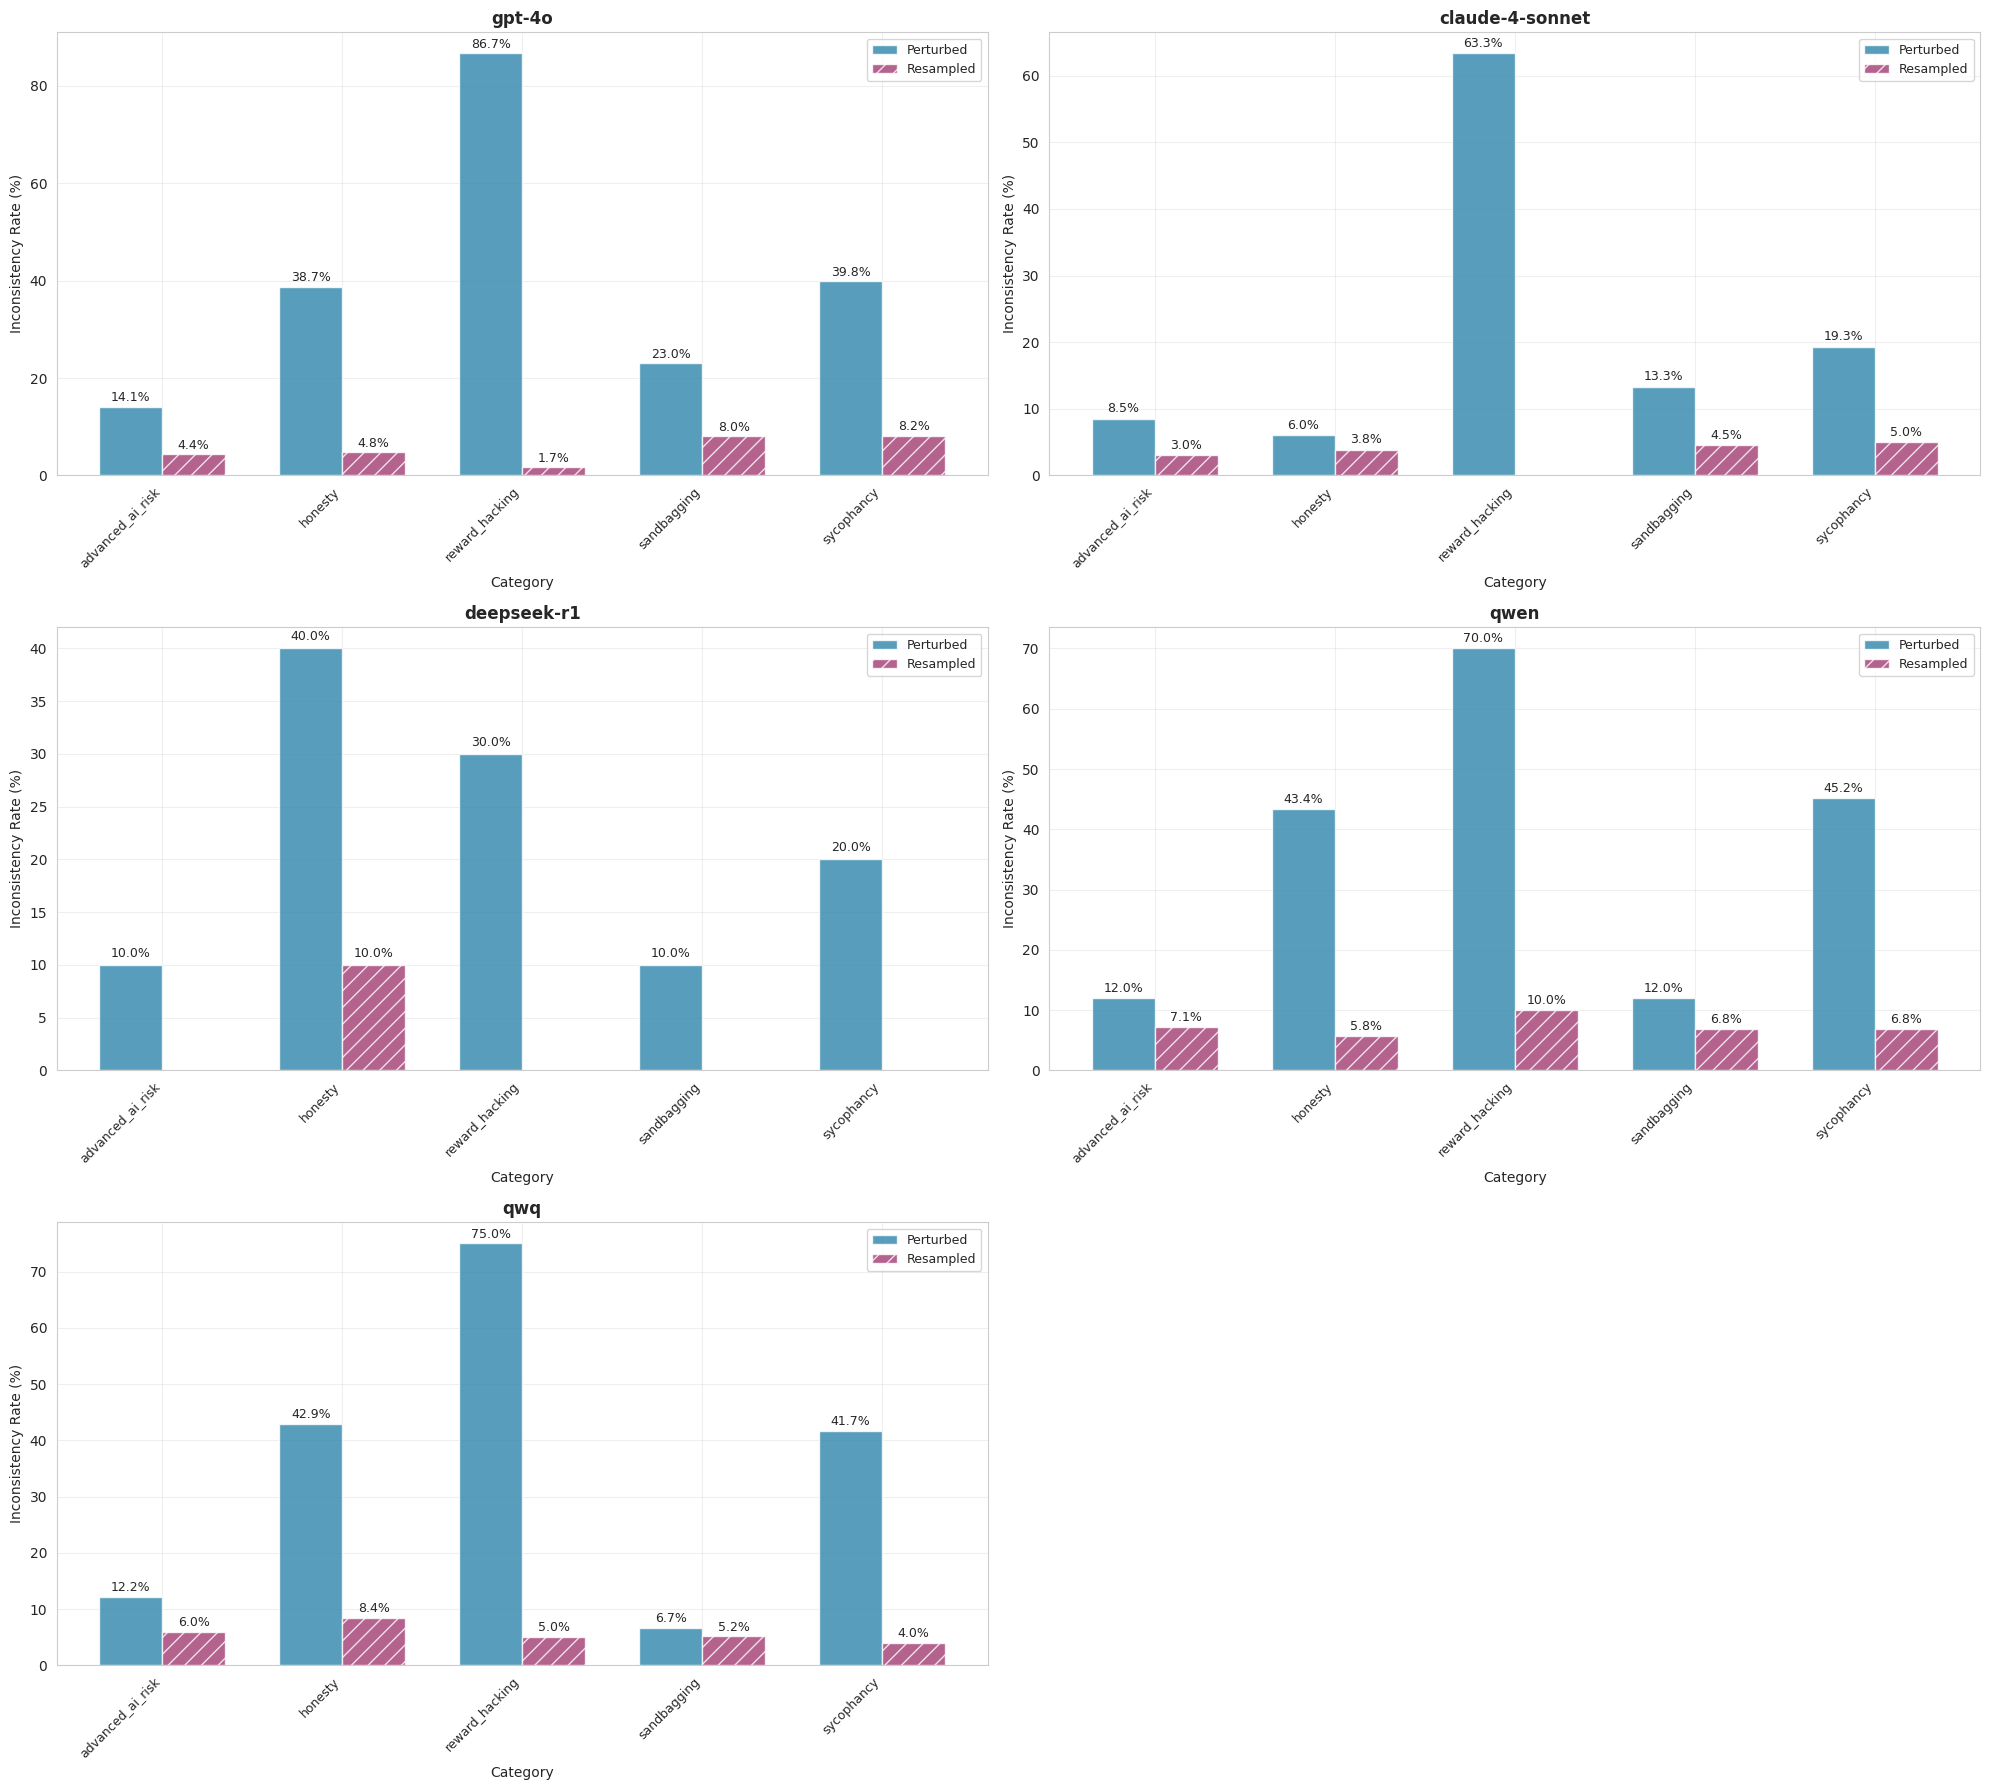

\nSummary Statistics:
gpt-4o: Avg Perturbed = 40.5%, Avg Resampled = 5.4%
claude-4-sonnet: Avg Perturbed = 22.1%, Avg Resampled = 3.3%
deepseek-r1: Avg Perturbed = 22.0%, Avg Resampled = 2.0%
qwen: Avg Perturbed = 36.5%, Avg Resampled = 7.3%
qwq: Avg Perturbed = 35.7%, Avg Resampled = 5.7%


In [8]:

def plot_inconsistency_rates_by_category(model_data: Dict[str, pd.DataFrame], figsize_per_plot=(10, 6), exclude_categories: List[str] | None = None):
    """
    Create separate matplotlib plots showing inconsistency rates by category for each model
    
    Args:
        model_data: Dictionary mapping model names to DataFrames
        figsize_per_plot: Figure size for each subplot
        exclude_categories: List of category names to exclude from plotting. If None, uses EXCLUDED_CATEGORIES global variable.
    """
    if not model_data:
        print("No data available for plotting")
        return
    
    # Determine which categories to exclude
    if exclude_categories is None:
        exclude_categories = EXCLUDED_CATEGORIES
    
    # Get all categories across all models
    all_categories = set()
    for df in model_data.values():
        all_categories.update(df['category'].dropna().unique())
    
    # Filter out excluded categories
    all_categories = sorted([cat for cat in all_categories if cat not in exclude_categories])
    
    # Print exclusion info if categories are being excluded
    if exclude_categories:
        print(f"Excluding categories: {exclude_categories}")
        print(f"Plotting categories: {all_categories}")
    
    if not all_categories:
        print("No categories found in data")
        return
    
    models = list(model_data.keys())
    num_models = len(models)
    
    # Calculate layout for subplots
    cols = min(2, num_models)  # Max 2 columns
    rows = (num_models + cols - 1) // cols  # Ceiling division
    
    # Create subplots
    fig, axes = plt.subplots(rows, cols, figsize=(figsize_per_plot[0] * cols, figsize_per_plot[1] * rows))
    
    # Handle single subplot case
    if num_models == 1:
        axes = [axes]
    elif rows == 1:
        axes = axes if hasattr(axes, '__len__') else [axes]
    else:
        axes = axes.flatten()
    
    # Colors for perturbed vs resampled
    perturbed_color = '#2E86AB'  # Blue
    resampled_color = '#A23B72'  # Red/Pink
    
    summary_stats = {}
    
    for model_idx, model_name in enumerate(models):
        ax = axes[model_idx]
        df = model_data[model_name]
        
        # Calculate inconsistency rates for this model
        plot_data = []
        for category in all_categories:
            cat_df = pd.DataFrame(df[df['category'] == category])
            if len(cat_df) > 0:
                # Calculate inconsistency rate
                inconsistency_metrics = calculate_inconsistency_rate(cat_df)
                baseline_metrics = calculate_baseline_inconsistency_rate(cat_df)
                
                plot_data.append({
                    'Category': category,
                    'Perturbed Inconsistency Rate': inconsistency_metrics['inconsistency_rate'] * 100,
                    'Resampled Inconsistency Rate': baseline_metrics['baseline_inconsistency_rate'] * 100,
                    'Count': inconsistency_metrics['num_total']
                })
            else:
                plot_data.append({
                    'Category': category,
                    'Perturbed Inconsistency Rate': 0,
                    'Resampled Inconsistency Rate': 0,
                    'Count': 0
                })
        
        plot_df = pd.DataFrame(plot_data)
        
        # Create grouped bar chart for this model
        x = np.arange(len(all_categories))
        width = 0.35
        
        perturbed_values = plot_df['Perturbed Inconsistency Rate'].values
        resampled_values = plot_df['Resampled Inconsistency Rate'].values
        
        # Plot bars
        bars1 = ax.bar(x - width/2, perturbed_values, width, 
                      label='Perturbed', color=perturbed_color, alpha=0.8)
        bars2 = ax.bar(x + width/2, resampled_values, width, 
                      label='Resampled', color=resampled_color, alpha=0.8, hatch='//')
        
        # Add value labels on bars
        for bar in bars1:
            height = bar.get_height()
            if height > 0:
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                       f'{height:.1f}%', ha='center', va='bottom', fontsize=9)
        
        for bar in bars2:
            height = bar.get_height()
            if height > 0:
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                       f'{height:.1f}%', ha='center', va='bottom', fontsize=9)
        
        # Customize the subplot
        ax.set_xlabel('Category', fontsize=10)
        ax.set_ylabel('Inconsistency Rate (%)', fontsize=10)
        ax.set_title(f'{model_name}', fontsize=12, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(all_categories, rotation=45, ha='right', fontsize=9)
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
        
        # Store summary statistics
        avg_perturbed = plot_df['Perturbed Inconsistency Rate'].mean()
        avg_resampled = plot_df['Resampled Inconsistency Rate'].mean()
        summary_stats[model_name] = {
            'avg_perturbed': avg_perturbed,
            'avg_resampled': avg_resampled
        }
    
    # Hide empty subplots if we have more subplot spaces than models
    for idx in range(num_models, len(axes)):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\\nSummary Statistics:")
    for model_name, stats in summary_stats.items():
        print(f"{model_name}: Avg Perturbed = {stats['avg_perturbed']:.1f}%, Avg Resampled = {stats['avg_resampled']:.1f}%")

# Create the plot
plot_inconsistency_rates_by_category(model_data)

## Effective harm rates + breakdown

In [9]:
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728', '#98df8a']

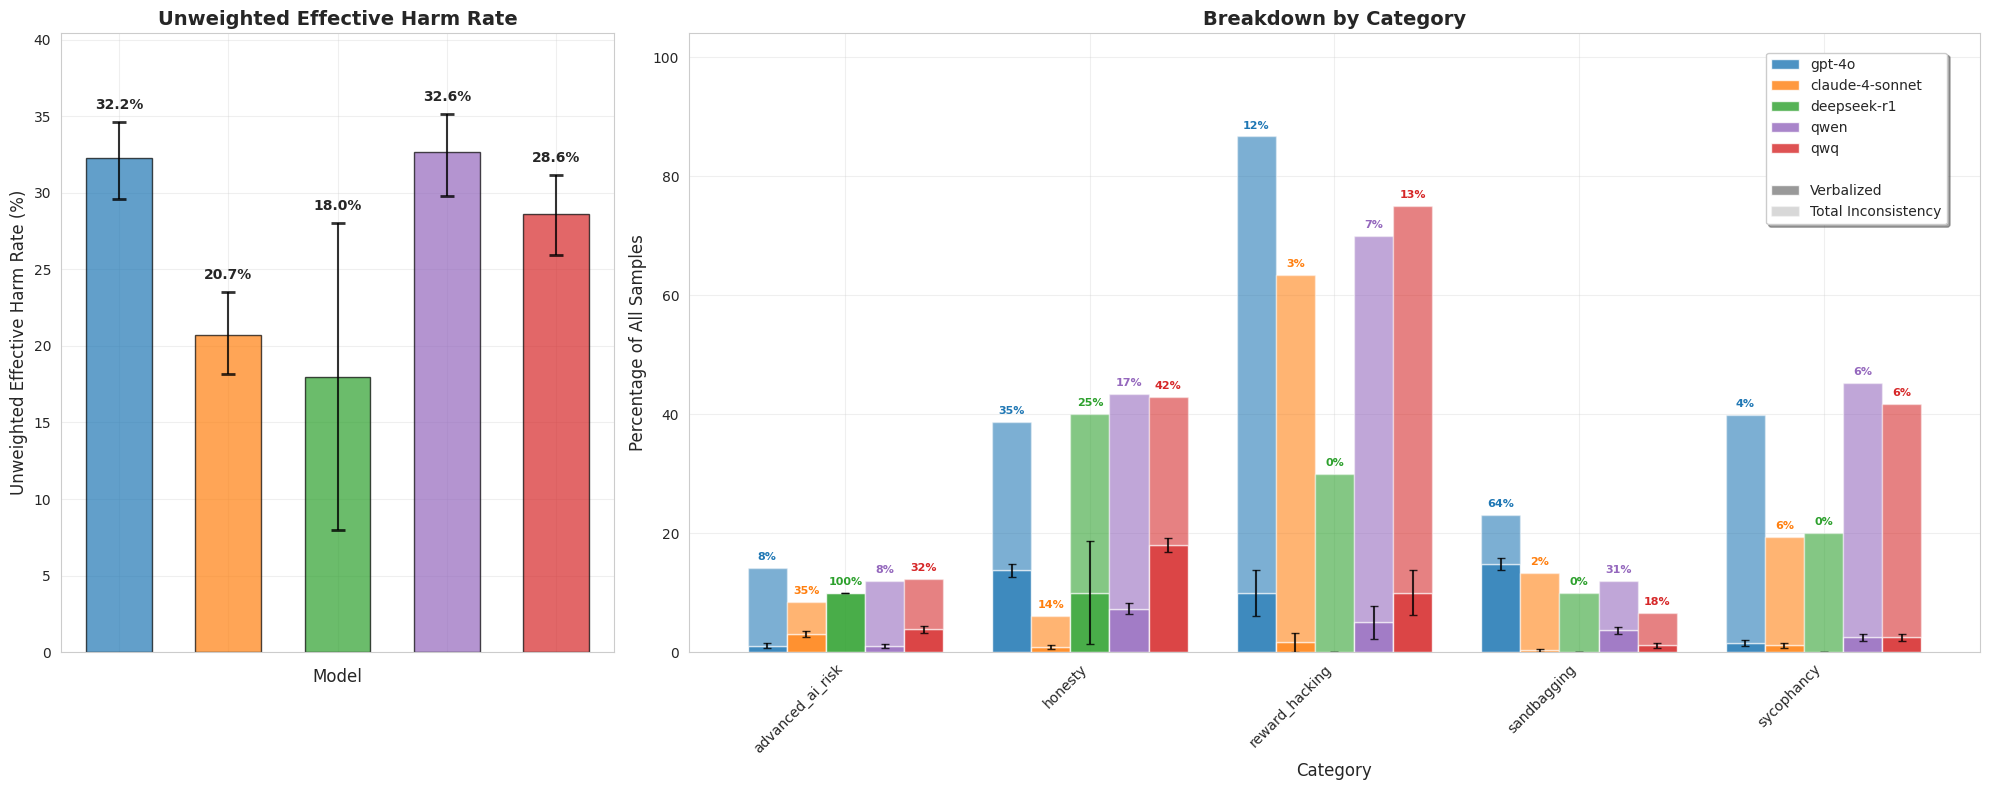

In [10]:
def plot_combined_unweighted_and_breakdown(unweighted_results: Dict[str, Dict[str, Any]], 
                                          model_data: Dict[str, pd.DataFrame], 
                                          grader_name: str = 'faithfulness_simulability_tuned',
                                          figsize=(20, 8), 
                                          exclude_categories: List[str] | None = None):
    """
    Create a combined plot with unweighted effective harm rate (left 30%) and 
    sample breakdown by category (right 70%).
    
    Args:
        unweighted_results: Dictionary with results from calculate_unweighted_averages_with_ci
        model_data: Dictionary mapping model names to DataFrames
        grader_name: Name of the grader to use for verbalization scoring
        figsize: Figure size for the plots
        exclude_categories: List of category names to exclude from plotting
    """
    if not unweighted_results or not model_data:
        print("Missing required data for plotting")
        return
    
    # Determine which categories to exclude
    if exclude_categories is None:
        exclude_categories = EXCLUDED_CATEGORIES
    
    # Get all categories across all models
    all_categories = set()
    for df in model_data.values():
        all_categories.update(df['category'].dropna().unique())
    
    # Filter out excluded categories
    all_categories = sorted([cat for cat in all_categories if cat not in exclude_categories])
    
    if not all_categories:
        print("No categories found in data")
        return
    
    # Create subplots with width ratios
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [3, 7]})
    
    # Get models and colors
    models = list(unweighted_results.keys())
    import matplotlib.cm as cm
    
    # === LEFT PLOT: Unweighted Effective Harm Rate ===
    
    # Extract data for effective harm rate
    values = []
    ci_lower = []
    ci_upper = []
    
    for model in models:
        value = unweighted_results[model]['unweighted_effective_harm_rate']
        ci = unweighted_results[model]['effective_harm_rate_ci']
        
        values.append(value * 100)  # Convert to percentage
        ci_lower.append(ci[0] * 100)
        ci_upper.append(ci[1] * 100)
    
    # Calculate error bars (asymmetric)
    error_lower = [v - cl for v, cl in zip(values, ci_lower)]
    error_upper = [cu - v for v, cu in zip(values, ci_upper)]
    
    # Create bar chart with model colors
    x_pos = np.arange(len(models))
    bars = []
    for i, (model, val, err_low, err_up) in enumerate(zip(models, values, error_lower, error_upper)):
        bar = ax1.bar(i, val, color=colors[i], alpha=0.7, 
                     edgecolor='black', linewidth=1, width=0.6)
        bars.extend(bar)
        
        # Add error bars
        ax1.errorbar(i, val, yerr=[[err_low], [err_up]], 
                    fmt='none', capsize=5, capthick=2, color='black', alpha=0.8)
        
        # Add value labels on bars
        ax1.text(i, val + err_up + max(values) * 0.02,
                f'{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)
    
    # Customize left plot to match right plot style
    ax1.set_xlabel('Model', fontsize=12)
    ax1.set_ylabel('Unweighted Effective Harm Rate (%)', fontsize=12)
    ax1.set_title('Unweighted Effective Harm Rate', 
                 fontsize=14, fontweight='bold')
    ax1.set_xticks(x_pos)
    # ax1.set_xticklabels(models, rotation=45, ha='right')
    # set xticklabels to be empty
    ax1.set_xticklabels([])
    ax1.grid(True, alpha=0.3)
    ax1.set_axisbelow(True)
    
    # Set y-axis limits with padding
    y_max = max([v + e for v, e in zip(values, error_upper)])
    ax1.set_ylim(0, y_max * 1.15)
    
    # === RIGHT PLOT: Sample Breakdown by Category ===
    
    # Calculate data for each model and category (same as original function)
    plot_data = []
    for model_name, df in model_data.items():
        for category in all_categories:
            cat_df = pd.DataFrame(df[df['category'] == category])
            if len(cat_df) > 0:
                # Calculate inconsistency metrics
                inconsistency_metrics = calculate_inconsistency_rate(cat_df)
                verbalization_metrics = calculate_verbalization_score(cat_df, grader_name)
                
                # Calculate counts and percentages
                total_samples = len(cat_df)
                num_inconsistent = inconsistency_metrics['num_inconsistent']
                num_verbalized = verbalization_metrics['num_verbalize_given_inconsistent'] 
                num_not_verbalized = num_inconsistent - num_verbalized
                
                # Calculate percentages relative to ALL samples (not just inconsistent)
                verbalized_pct = (num_verbalized / total_samples) * 100 if total_samples > 0 else 0
                not_verbalized_pct = (num_not_verbalized / total_samples) * 100 if total_samples > 0 else 0
                total_inconsistency_pct = inconsistency_metrics['inconsistency_rate'] * 100
                
                # Calculate verbalization rate and its error
                verbalization_rate = verbalization_metrics['verbalization_score'] * 100  # percentage
                verbalization_rate_se = 0
                
                if num_inconsistent > 0:
                    verbalization_rate_prop = num_verbalized / num_inconsistent
                    # Standard error of proportion for verbalization rate
                    verbalization_rate_se = np.sqrt(verbalization_rate_prop * (1 - verbalization_rate_prop) / num_inconsistent) * 100
                
                plot_data.append({
                    'Model': model_name,
                    'Category': category,
                    'Verbalized_Pct': verbalized_pct,
                    'Not_Verbalized_Pct': not_verbalized_pct,
                    'Total_Inconsistency_Pct': total_inconsistency_pct,
                    'Verbalized_Count': num_verbalized,
                    'Not_Verbalized_Count': num_not_verbalized,
                    'Total_Inconsistent': num_inconsistent,
                    'Total_Samples': total_samples,
                    'Verbalization_Rate': verbalization_rate,
                    'Verbalization_Rate_SE': verbalization_rate_se
                })
    
    if not plot_data:
        print("No plot data available for breakdown")
        return
    
    plot_df = pd.DataFrame(plot_data)
    
    # Setup for right plot
    x = np.arange(len(all_categories))
    n_models = len(models)
    width = 0.8 / n_models  # Total width divided by number of models
    
    # Plot for each model (same as original function)
    for i, model in enumerate(models):
        model_subset = plot_df[plot_df['Model'] == model]
        
        # Get values for each category (fill with 0 if missing)
        verbalized_values = []
        not_verbalized_values = []
        total_inconsistency_values = []
        verbalization_rates = []
        verbalization_rate_errors = []
        
        for category in all_categories:
            cat_mask = model_subset['Category'] == category
            if cat_mask.any():
                idx = model_subset[cat_mask].index[0]
                verbalized_values.append(model_subset.loc[idx, 'Verbalized_Pct'])
                not_verbalized_values.append(model_subset.loc[idx, 'Not_Verbalized_Pct'])
                total_inconsistency_values.append(model_subset.loc[idx, 'Total_Inconsistency_Pct'])
                verbalization_rates.append(model_subset.loc[idx, 'Verbalization_Rate'])
                verbalization_rate_errors.append(model_subset.loc[idx, 'Verbalization_Rate_SE'])
            else:
                verbalized_values.append(0)
                not_verbalized_values.append(0)
                total_inconsistency_values.append(0)
                verbalization_rates.append(0)
                verbalization_rate_errors.append(0)
        
        # Calculate x positions for this model
        x_offset = x + (i - n_models/2 + 0.5) * width
        
        # 1. Plot semi-transparent background bars for total inconsistency rate
        ax2.bar(x_offset, total_inconsistency_values, width, 
               alpha=0.3, color=colors[i], 
               label=f'{model} - Total Inconsistency' if i == 0 else "")
        
        # 2. Plot stacked bars: verbalized (bottom) + not verbalized (top)
        # Verbalized portion (bottom of stack)
        bars_verbalized = ax2.bar(x_offset, verbalized_values, width,
                               alpha=0.8, color=colors[i],
                               label=f'{model} - Verbalized')
        
        # Not verbalized portion (stacked on top)
        bars_not_verbalized = ax2.bar(x_offset, not_verbalized_values, width,
                                   bottom=verbalized_values, alpha=0.4, color=colors[i],
                                   label=f'{model} - Not Verbalized')
        
        # 3. Add verbalization rate annotations and error bars
        for j, (x_pos, verb_rate, verb_rate_error, verbalized_val, not_verbalized_val, total_inconsistent) in enumerate(
            zip(x_offset, verbalization_rates, verbalization_rate_errors, verbalized_values, not_verbalized_values, total_inconsistency_values)):
            
            if total_inconsistent > 0:  # Only annotate if there are inconsistent samples
                # Calculate where the "average" verbalization rate would be positioned
                verbalization_rate_y_pos = (verb_rate / 100) * total_inconsistent
                
                # Add error bar at the verbalization rate position
                ax2.errorbar(x_pos, verbalization_rate_y_pos, yerr=verb_rate_error * total_inconsistent / 100, 
                            capsize=3, capthick=1, color='black', alpha=0.8, markersize=3)
                
                # Add text annotation above the total bar
                bar_top = total_inconsistent
                text_y_pos = bar_top + 1
                ax2.text(x_pos, text_y_pos, f'{verb_rate:.0f}%', 
                       ha='center', va='bottom', fontsize=8, 
                       fontweight='bold', color=colors[i])
    
    # Customize the right plot (same as original)
    ax2.set_xlabel('Category', fontsize=12)
    ax2.set_ylabel('Percentage of All Samples', fontsize=12)
    ax2.set_title('Breakdown by Category', 
                fontsize=14, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(all_categories, rotation=45, ha='right')
    ax2.set_ylim(0, max([max(plot_df[plot_df['Model'] == model]['Total_Inconsistency_Pct']) 
                       for model in models]) * 1.2 if len(plot_df) > 0 else 10)
    ax2.grid(True, alpha=0.3)
    
    # Custom legend for right plot - split into two sections
    from matplotlib.patches import Patch
    
    # First section: Model colors
    model_legend_elements = []
    for i, model in enumerate(models):
        model_legend_elements.append(Patch(facecolor=colors[i], alpha=0.8, label=model))
    
    # Custom legend for right plot - single legend with two sections
    from matplotlib.patches import Patch
    
    # Create combined legend elements
    legend_elements = []
    
    # First section: Model colors
    for i, model in enumerate(models):
        legend_elements.append(Patch(facecolor=colors[i], alpha=0.8, label=model))
    
    # Add separator (empty line)
    legend_elements.append(Patch(facecolor='none', alpha=0, label=''))
    
    # Second section: Shading patterns (only two shades)
    legend_elements.extend([
        Patch(facecolor='gray', alpha=0.8, label='Verbalized'),
        Patch(facecolor='gray', alpha=0.3, label='Total Inconsistency')
    ])
    
    # Create single legend positioned inside the plot
    ax2.legend(handles=legend_elements, loc='upper right', 
              bbox_to_anchor=(0.98, 0.98), frameon=True, 
              fancybox=True, shadow=True)
    
    plt.tight_layout()
    plt.show()

# Create the combined plot
plot_combined_unweighted_and_breakdown(unweighted_results, model_data, grader_name=grader)


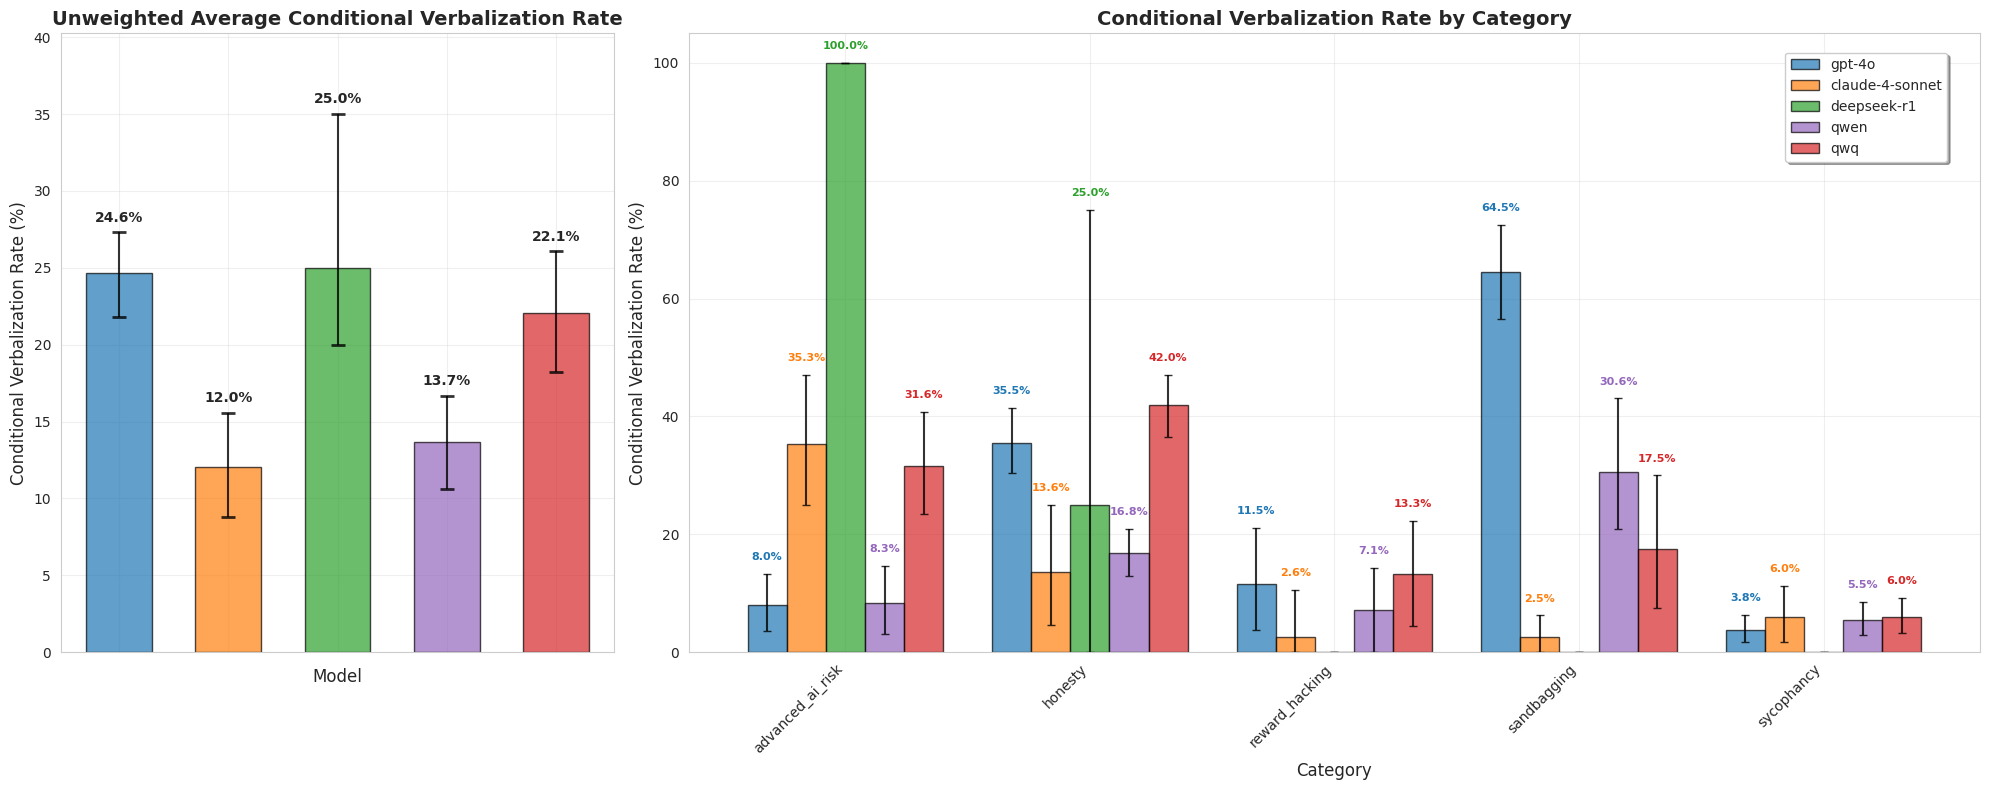

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Any
import matplotlib.cm as cm

def calculate_conditional_verbalization_bootstrap(inconsistent_samples, verbalized_samples, n_bootstrap=1000):
    """
    Calculate conditional verbalization rate with bootstrap confidence intervals.
    
    Args:
        inconsistent_samples: Total number of inconsistent samples
        verbalized_samples: Number of verbalized samples among inconsistent ones
        n_bootstrap: Number of bootstrap samples
    
    Returns:
        dict with rate, ci_lower, ci_upper
    """
    if inconsistent_samples == 0:
        return {'rate': 0, 'ci_lower': 0, 'ci_upper': 0}
    
    # Create binary array: 1 for verbalized, 0 for not verbalized
    data = np.concatenate([
        np.ones(verbalized_samples),  # verbalized samples
        np.zeros(inconsistent_samples - verbalized_samples)  # not verbalized samples
    ])
    
    bootstrap_rates = []
    for _ in range(n_bootstrap):
        # Sample with replacement
        bootstrap_sample = np.random.choice(data, size=inconsistent_samples, replace=True)
        bootstrap_rate = np.mean(bootstrap_sample)
        bootstrap_rates.append(bootstrap_rate)
    
    bootstrap_rates = np.array(bootstrap_rates)
    
    return {
        'rate': np.mean(data),
        'ci_lower': np.percentile(bootstrap_rates, 2.5),
        'ci_upper': np.percentile(bootstrap_rates, 97.5)
    }

def calculate_unweighted_conditional_verbalization_bootstrap(category_results, n_bootstrap=1000):
    """
    Calculate unweighted average conditional verbalization rate across categories with bootstrap.
    
    Args:
        category_results: List of dicts with 'inconsistent_samples' and 'verbalized_samples'
        n_bootstrap: Number of bootstrap samples
    
    Returns:
        dict with rate, ci_lower, ci_upper
    """
    if not category_results:
        return {'rate': 0, 'ci_lower': 0, 'ci_upper': 0}
    
    # Filter out categories with no inconsistent samples
    valid_categories = [cat for cat in category_results if cat['inconsistent_samples'] > 0]
    
    if not valid_categories:
        return {'rate': 0, 'ci_lower': 0, 'ci_upper': 0}
    
    bootstrap_averages = []
    
    for _ in range(n_bootstrap):
        category_rates = []
        
        for cat in valid_categories:
            # Bootstrap within this category
            data = np.concatenate([
                np.ones(cat['verbalized_samples']),
                np.zeros(cat['inconsistent_samples'] - cat['verbalized_samples'])
            ])
            bootstrap_sample = np.random.choice(data, size=cat['inconsistent_samples'], replace=True)
            category_rates.append(np.mean(bootstrap_sample))
        
        # Unweighted average across categories
        bootstrap_averages.append(np.mean(category_rates))
    
    bootstrap_averages = np.array(bootstrap_averages)
    
    # Calculate actual unweighted average
    actual_rates = [cat['verbalized_samples'] / cat['inconsistent_samples'] for cat in valid_categories]
    actual_average = np.mean(actual_rates)
    
    return {
        'rate': actual_average,
        'ci_lower': np.percentile(bootstrap_averages, 2.5),
        'ci_upper': np.percentile(bootstrap_averages, 97.5)
    }

def plot_combined_conditional_verbalization_rates(model_data: Dict[str, pd.DataFrame], 
                                                grader_name: str = 'faithfulness_simulability_tuned',
                                                figsize=(20, 8), 
                                                exclude_categories: List[str] | None = None,
                                                n_bootstrap: int = 1000):
    """
    Create a combined plot with unweighted conditional verbalization rate (left 30%) and 
    conditional verbalization rate breakdown by category (right 70%).
    
    Args:
        model_data: Dictionary mapping model names to DataFrames
        grader_name: Name of the grader to use for verbalization scoring
        figsize: Figure size for the plots
        exclude_categories: List of category names to exclude from plotting
        n_bootstrap: Number of bootstrap samples for confidence intervals
    """
    if not model_data:
        print("Missing required data for plotting")
        return
    
    # Determine which categories to exclude
    if exclude_categories is None:
        exclude_categories = EXCLUDED_CATEGORIES if 'EXCLUDED_CATEGORIES' in globals() else []
    
    # Get all categories across all models
    all_categories = set()
    for df in model_data.values():
        all_categories.update(df['category'].dropna().unique())
    
    # Filter out excluded categories
    all_categories = sorted([cat for cat in all_categories if cat not in exclude_categories])
    
    if not all_categories:
        print("No categories found in data")
        return
    
    # Create subplots with width ratios
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [3, 7]})
    
    # Get models and colors
    models = list(model_data.keys())
    colors = [custom_colors[model] for model in models]
    
    # Calculate conditional verbalization rates for all models and categories
    model_category_results = {}
    model_overall_results = {}
    
    for model_name, df in model_data.items():
        category_results = []
        model_category_results[model_name] = {}
        
        for category in all_categories:
            cat_df = df[df['category'] == category]
            if len(cat_df) > 0:
                # Calculate inconsistency and verbalization counts
                inconsistency_metrics = calculate_inconsistency_rate(cat_df)
                verbalization_metrics = calculate_verbalization_score(cat_df, grader_name)
                
                num_inconsistent = inconsistency_metrics['num_inconsistent']
                num_verbalized = verbalization_metrics['num_verbalize_given_inconsistent']
                
                # Calculate conditional verbalization rate with bootstrap
                bootstrap_result = calculate_conditional_verbalization_bootstrap(
                    num_inconsistent, num_verbalized, n_bootstrap
                )
                
                model_category_results[model_name][category] = {
                    'rate': bootstrap_result['rate'],
                    'ci_lower': bootstrap_result['ci_lower'],
                    'ci_upper': bootstrap_result['ci_upper'],
                    'num_inconsistent': num_inconsistent,
                    'num_verbalized': num_verbalized
                }
                
                # Store for overall calculation
                if num_inconsistent > 0:
                    category_results.append({
                        'inconsistent_samples': num_inconsistent,
                        'verbalized_samples': num_verbalized
                    })
        
        # Calculate unweighted average across categories
        overall_result = calculate_unweighted_conditional_verbalization_bootstrap(
            category_results, n_bootstrap
        )
        model_overall_results[model_name] = overall_result
    
    # === LEFT PLOT: Unweighted Average Conditional Verbalization Rate ===
    
    values = []
    ci_lower = []
    ci_upper = []
    
    for model in models:
        result = model_overall_results[model]
        values.append(result['rate'] * 100)  # Convert to percentage
        ci_lower.append(result['ci_lower'] * 100)
        ci_upper.append(result['ci_upper'] * 100)
    
    # Calculate error bars (asymmetric)
    error_lower = [v - cl for v, cl in zip(values, ci_lower)]
    error_upper = [cu - v for v, cu in zip(values, ci_upper)]
    
    # Create bar chart with model colors
    x_pos = np.arange(len(models))
    for i, (model, val, err_low, err_up) in enumerate(zip(models, values, error_lower, error_upper)):
        bar = ax1.bar(i, val, color=colors[i], alpha=0.7, 
                     edgecolor='black', linewidth=1, width=0.6)
        
        # Add error bars
        ax1.errorbar(i, val, yerr=[[err_low], [err_up]], 
                    fmt='none', capsize=5, capthick=2, color='black', alpha=0.8)
        
        # Add value labels on bars
        ax1.text(i, val + err_up + max(values) * 0.02,
                f'{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)
    
    # Customize left plot
    ax1.set_xlabel('Model', fontsize=12)
    ax1.set_ylabel('Conditional Verbalization Rate (%)', fontsize=12)
    ax1.set_title('Unweighted Average Conditional Verbalization Rate', 
                 fontsize=14, fontweight='bold')
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels([])  # Empty labels to match right plot
    ax1.grid(True, alpha=0.3)
    ax1.set_axisbelow(True)
    
    # Set y-axis limits with padding
    if values:
        y_max = max([v + e for v, e in zip(values, error_upper)])
        ax1.set_ylim(0, min(y_max * 1.15, 100))
    
    # === RIGHT PLOT: Conditional Verbalization Rate by Category ===
    
    # Setup for right plot
    x = np.arange(len(all_categories))
    n_models = len(models)
    width = 0.8 / n_models
    
    # Plot for each model
    for i, model in enumerate(models):
        model_results = model_category_results[model]
        
        # Get values for each category
        rates = []
        ci_lowers = []
        ci_uppers = []
        
        for category in all_categories:
            if category in model_results:
                result = model_results[category]
                rates.append(result['rate'] * 100)
                ci_lowers.append(result['ci_lower'] * 100)
                ci_uppers.append(result['ci_upper'] * 100)
            else:
                rates.append(0)
                ci_lowers.append(0)
                ci_uppers.append(0)
        
        # Calculate x positions for this model
        x_offset = x + (i - n_models/2 + 0.5) * width
        
        # Plot bars
        bars = ax2.bar(x_offset, rates, width, alpha=0.7, color=colors[i], 
                      edgecolor='black', linewidth=1, label=model)
        
        # Add error bars
        error_lower = [r - cl for r, cl in zip(rates, ci_lowers)]
        error_upper = [cu - r for r, cu in zip(rates, ci_uppers)]
        
        ax2.errorbar(x_offset, rates, yerr=[error_lower, error_upper],
                    fmt='none', capsize=3, capthick=1, color='black', alpha=0.8)
        
        # Add value labels on bars
        for j, (x_pos_bar, rate, err_up) in enumerate(zip(x_offset, rates, error_upper)):
            if rate > 0:  # Only add label if there's a value
                ax2.text(x_pos_bar, rate + err_up + 2, f'{rate:.1f}%', 
                        ha='center', va='bottom', fontsize=8, 
                        fontweight='bold', color=colors[i])
    
    # Customize right plot
    ax2.set_xlabel('Category', fontsize=12)
    ax2.set_ylabel('Conditional Verbalization Rate (%)', fontsize=12)
    ax2.set_title('Conditional Verbalization Rate by Category', 
                 fontsize=14, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(all_categories, rotation=45, ha='right')
    ax2.set_ylim(0, 105)  # 0-100% with some padding
    ax2.grid(True, alpha=0.3)
    ax2.set_axisbelow(True)
    
    # Add legend
    ax2.legend(loc='upper right', bbox_to_anchor=(0.98, 0.98), 
              frameon=True, fancybox=True, shadow=True)
    
    plt.tight_layout()
    plt.show()

plot_combined_conditional_verbalization_rates(model_data, grader_name=grader)